In [3]:
!pip install -q sktime


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.6/37.6 MB 51.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.3/165.3 kB 14.8 MB/s eta 0:00:00


In [6]:
!pip install "ml_dtypes>=0.5" --upgrade


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 71.1 MB/s eta 0:00:00
  Attempting uninstall: ml_dtypes
    Found existing installation: ml-dtypes 0.3.2
    Uninstalling ml-dtypes-0.3.2:
      Successfully uninstalled ml-dtypes-0.3.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.16.1 requires ml-dtypes~=0.3.1, but you have ml-dtypes 0.5.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
tf-keras 2.20.0 requires tensorflow<2.21,>=2.20, but you have tensorflow 2.16.1 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.16.1 which is incompatible.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.16.1 which is incompatible.


In [1]:
import io
import os
import sys
import random
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

SEED = 42

np.random.seed(SEED)
random.seed(SEED)


In [ ]:
# Load ECG5000 - corrected version
def _parse_ecg_dataframe(file_obj):

    df = pd.read_csv(
        file_obj,
        sep=r"\s+",
        header=None,
        engine="python"
    )

    df = df.dropna(axis=1, how="all")

    if df.shape[1] < 141:
        raise ValueError(
            f"{df.shape[1]} "
        )

    y = df.iloc[:, 0].astype(float).astype(int).to_numpy()
    X = df.iloc[:, 1:141].astype(float).to_numpy()

    if X.shape[1] != 140:
        raise ValueError(
            f" {X.shape[1]} "
        )

    return X, y


def _try_direct_zip():

    url = "https://timeseriesclassification.com/aeon-toolkit/ECG5000.zip"

    with urllib.request.urlopen(url, timeout=60) as resp:
        data = resp.read()

    with zipfile.ZipFile(io.BytesIO(data)) as zf:

        names = zf.namelist()

        train_candidates = [
            n for n in names
            if "TRAIN" in n.upper()
            and n.upper().endswith((".TXT", ".TSV", ".CSV"))
        ]

        test_candidates = [
            n for n in names
            if "TEST" in n.upper()
            and n.upper().endswith((".TXT", ".TSV", ".CSV"))
        ]

        if not train_candidates or not test_candidates:
            raise FileNotFoundError(
                " TRAIN و TEST  ZIP  no."
            )

        train_name = train_candidates[0]
        test_name = test_candidates[0]

        print("Train file:", train_name)
        print("Test file :", test_name)

        with zf.open(train_name) as f:
            X_train, y_train = _parse_ecg_dataframe(f)

        with zf.open(test_name) as f:
            X_test, y_test = _parse_ecg_dataframe(f)

    return X_train, y_train, X_test, y_test


def _try_sktime():

    from sktime.datasets import load_UCR_UEA_dataset

    X_train, y_train = load_UCR_UEA_dataset(
        name="ECG5000",
        split="train",
        return_type="numpy2d"
    )

    X_test, y_test = load_UCR_UEA_dataset(
        name="ECG5000",
        split="test",
        return_type="numpy2d"
    )

    return (
        X_train.astype(float),
        np.asarray(y_train).astype(int),
        X_test.astype(float),
        np.asarray(y_test).astype(int)
    )


def _try_local_upload():

    train_path = "ECG5000_TRAIN.txt"
    test_path = "ECG5000_TEST.txt"

    if not (os.path.exists(train_path) and os.path.exists(test_path)):
        raise FileNotFoundError(
            " ECG5000_TRAIN.txt و ECG5000_TEST.txt no"
        )

    with open(train_path, "rb") as f:
        X_train, y_train = _parse_ecg_dataframe(f)

    with open(test_path, "rb") as f:
        X_test, y_test = _parse_ecg_dataframe(f)

    return X_train, y_train, X_test, y_test


def load_ecg5000():

    methods = [
        ("direct_zip", _try_direct_zip),
        ("sktime", _try_sktime),
        ("local_upload", _try_local_upload),
    ]

    last_error = None

    for name, fn in methods:
        try:
            print(f"[load_ecg5000] Trying method: {name} ...")

            X_train, y_train, X_test, y_test = fn()

            print(f"[load_ecg5000] Success via: {name}")
            return X_train, y_train, X_test, y_test

        except Exception as e:
            print(f"[load_ecg5000] Method '{name}' failed: {e}")
            last_error = e

    raise RuntimeError(
        "ECG5000 no"
    ) from last_error


X_train_raw, y_train_raw, X_test_raw, y_test_raw = load_ecg5000()

print("X_train_raw:", X_train_raw.shape)
print("y_train_raw classes:",
      np.unique(y_train_raw, return_counts=True))

print("X_test_raw :", X_test_raw.shape)
print("y_test_raw classes:",
      np.unique(y_test_raw, return_counts=True))

assert X_train_raw.shape[1] == 140
assert X_test_raw.shape[1] == 140


[load_ecg5000] Trying method: direct_zip ...
Train file: ECG5000_TRAIN.txt
Test file : ECG5000_TEST.txt
[load_ecg5000] Success via: direct_zip
X_train_raw: (500, 140)
y_train_raw classes: (array([1, 2, 3, 4, 5]), array([292, 177,  10,  19,   2]))
X_test_raw : (4500, 140)
y_test_raw classes: (array([1, 2, 3, 4, 5]), array([2627, 1590,   86,  175,   22]))


train-normal: (233, 140)
val-normal  : (59, 140)
test total  : (4500, 140) | test-normal: 2627 | test-abnormal: 1873
  test class 1: 2627 samples
  test class 2: 1590 samples
  test class 3: 86 samples
  test class 4: 175 samples
  test class 5: 22 samples
NaN/Inf check: OK

--- Sample counts summary ---
train-normal      : 233
validation-normal : 59
test-normal       : 2627
test-abnormal     : 1873


Model: "dense_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 140)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_64 (Dense)            │ (None, 64)             │         9,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_dense_32 (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense_32 (Dense)            │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense_64 (Dense)            │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 140)            │         9,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,868 (89.33 KB)

 Trainable params: 22,868 (89.33 KB)

 Non-trainable params: 0 (0.00 B)

Total trainable params: 22868
Epoch 1/200
4/4 - 6s - 2s/step - loss: 1.0116 - val_loss: 0.9469
Epoch 2/200
4/4 - 0s - 81ms/step - loss: 0.9918 - val_loss: 0.9382
Epoch 3/200
4/4 - 1s - 129ms/step - loss: 0.9711 - val_loss: 0.9243
Epoch 4/200
4/4 - 0s - 54ms/step - loss: 0.9391 - val_loss: 0.9014
Epoch 5/200
4/4 - 0s - 81ms/step - loss: 0.8814 - val_loss: 0.8683
Epoch 6/200
4/4 - 0s - 103ms/step - loss: 0.8293 - val_loss: 0.8344
Epoch 7/200
4/4 - 0s - 102ms/step - loss: 0.7669 - val_loss: 0.7985
Epoch 8/200
4/4 - 0s - 55ms/step - loss: 0.6999 - val_loss: 0.7559
Epoch 9/200
4/4 - 0s - 96ms/step - loss: 0.6395 - val_loss: 0.7103
Epoch 10/200
4/4 - 0s - 90ms/step - loss: 0.5813 - val_loss: 0.6659
Epoch 11/200
4/4 - 0s - 54ms/step - loss: 0.5391 - val_loss: 0.6290
Epoch 12/200
4/4 - 0s - 66ms/step - loss: 0.4978 - val_loss: 0.5944
Epoch 13/200
4/4 - 0s - 27ms/step - loss: 0.4627 - val_loss: 0.5603
Epoch 14/200
4/4 - 0s - 26ms/step - loss: 0.4312 - val_loss: 0.5298
Epoch 15/200
4/4 - 0s - 26

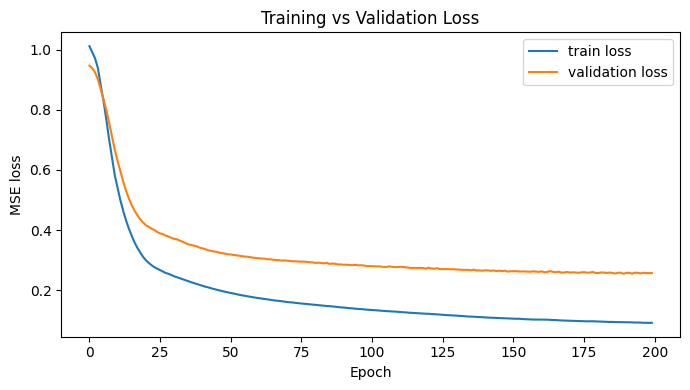

val-normal error   : mean=0.25492 std=0.92813
test-normal error  : mean=0.19707 std=0.48411
test-abnormal error: mean=1.94718 std=1.58389
Base threshold (95th percentile of validation-normal): 0.351620

--- Threshold sweep on validation-normal only (no test leakage) ---
 percentile  threshold  val_normal_false_positive_rate
         90   0.257974                        0.101695
         92   0.280035                        0.084746
         94   0.310713                        0.067797
         95   0.351620                        0.050847
         96   0.465522                        0.050847
         97   0.583976                        0.033898
         98   0.708032                        0.033898
         99   3.483932                        0.016949

Final threshold used for test evaluation: 0.351620
=== Final test metrics (threshold = 0.351620) ===
Precision : 0.9028
Recall    : 0.9968
F1        : 0.9475
Accuracy  : 0.9540  <-- NOTE: due to class imbalance, accuracy is NOT the p

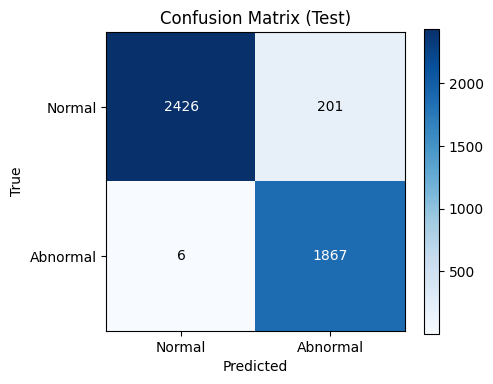

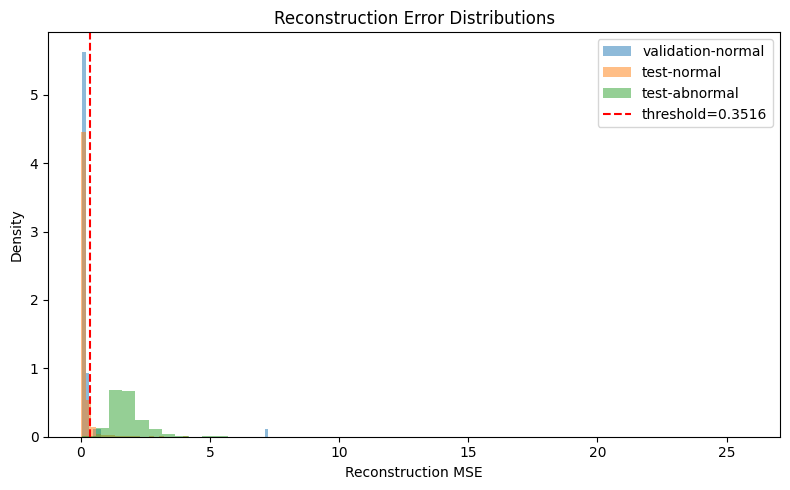

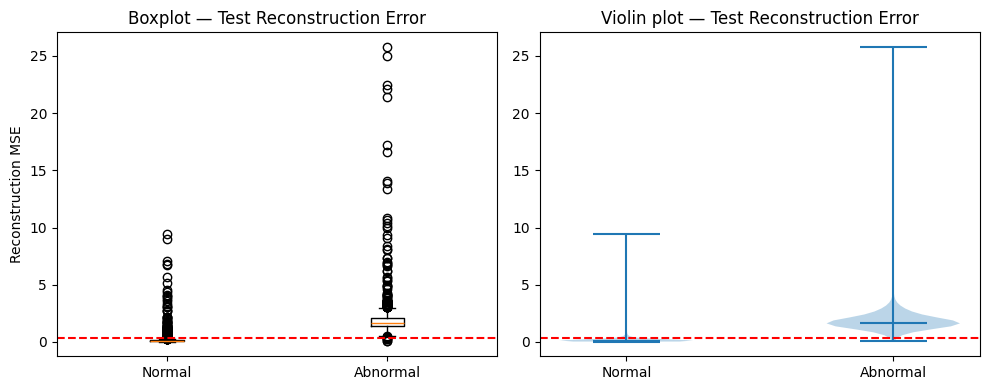

=== True Positives ===


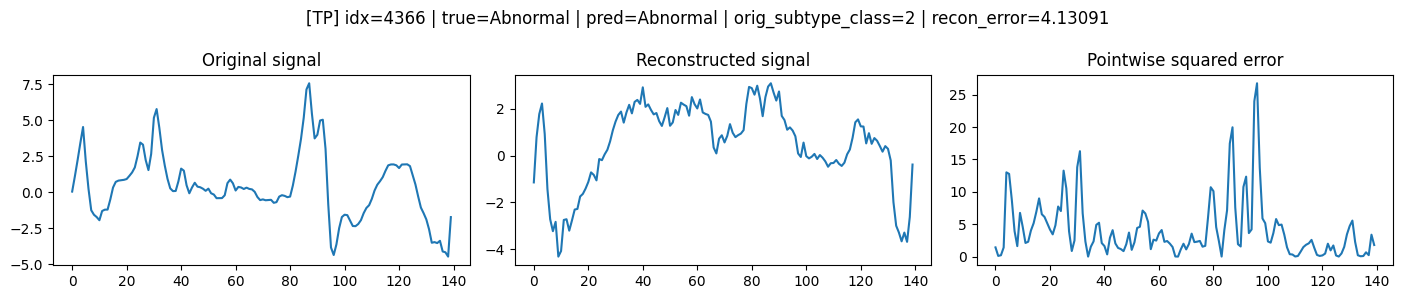

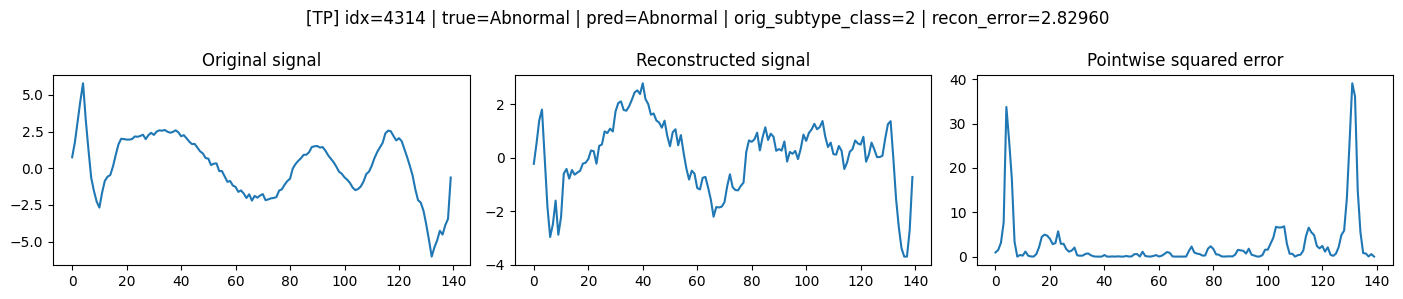

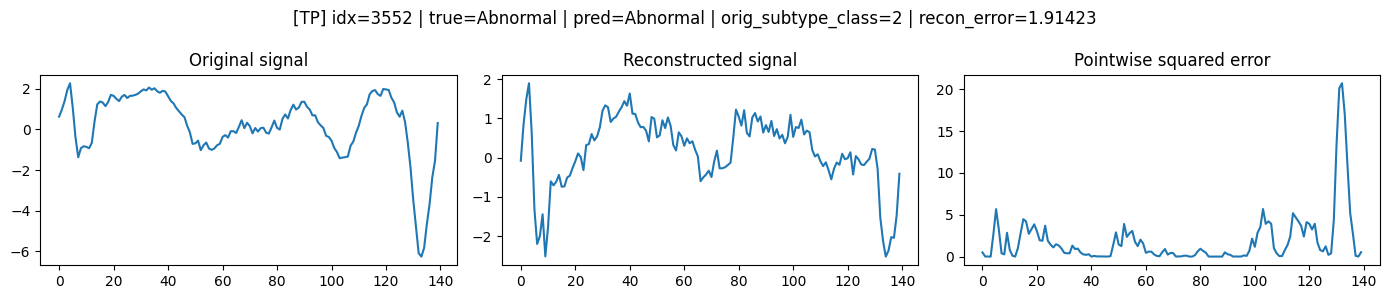

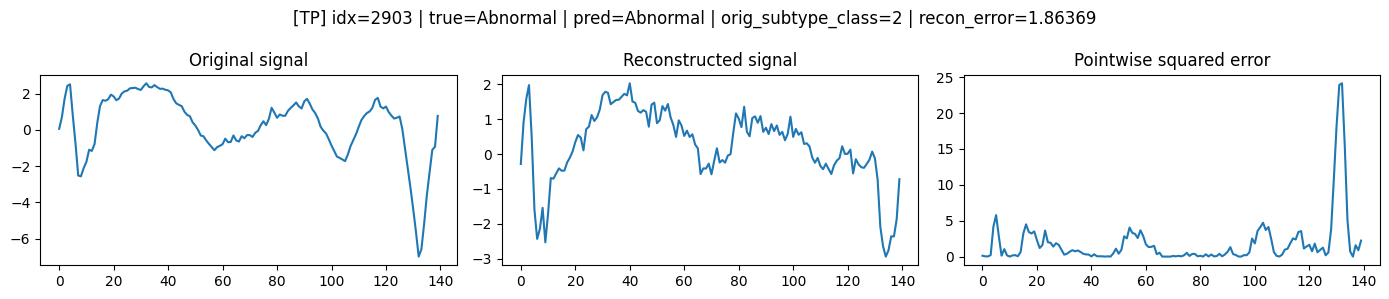

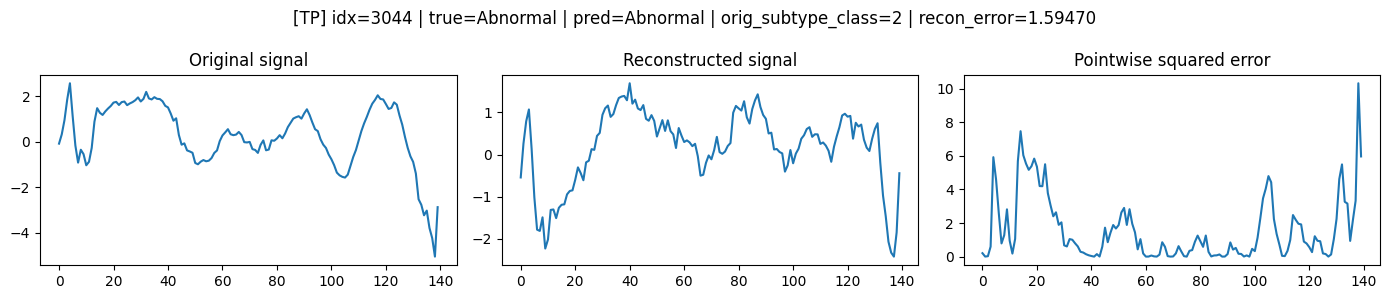

=== False Positives ===


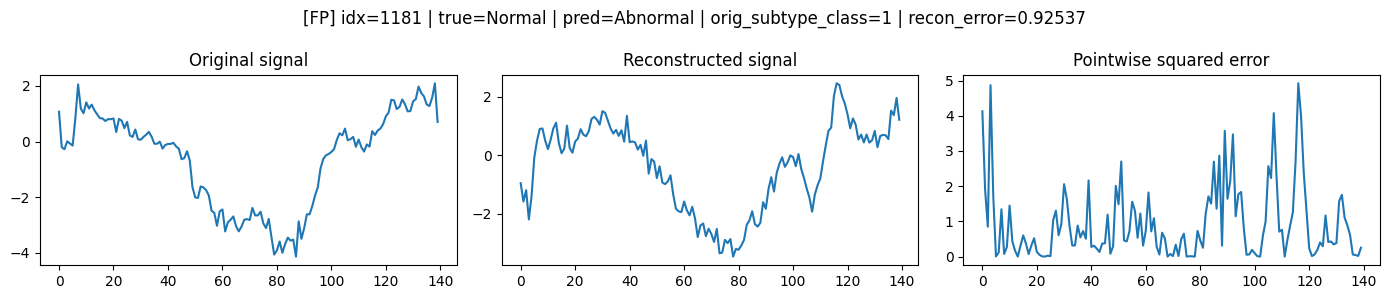

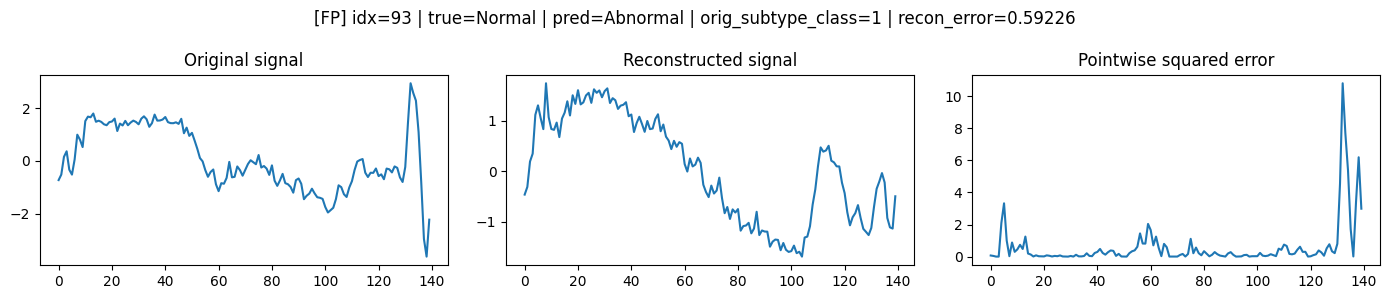

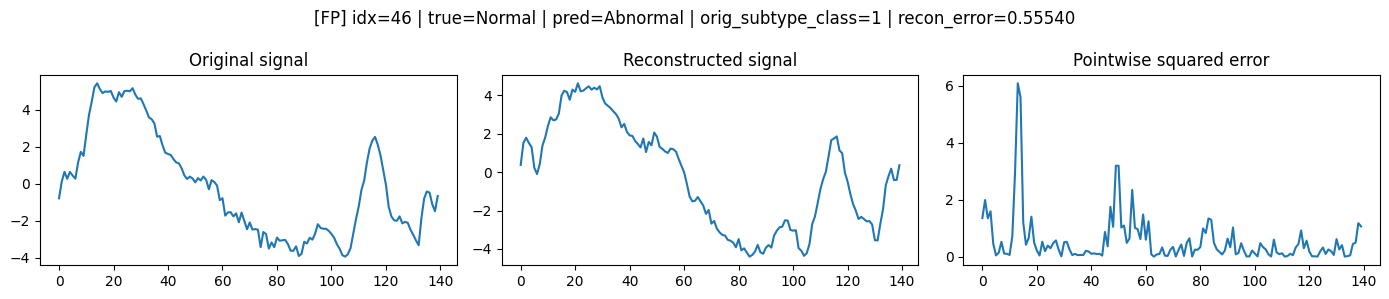

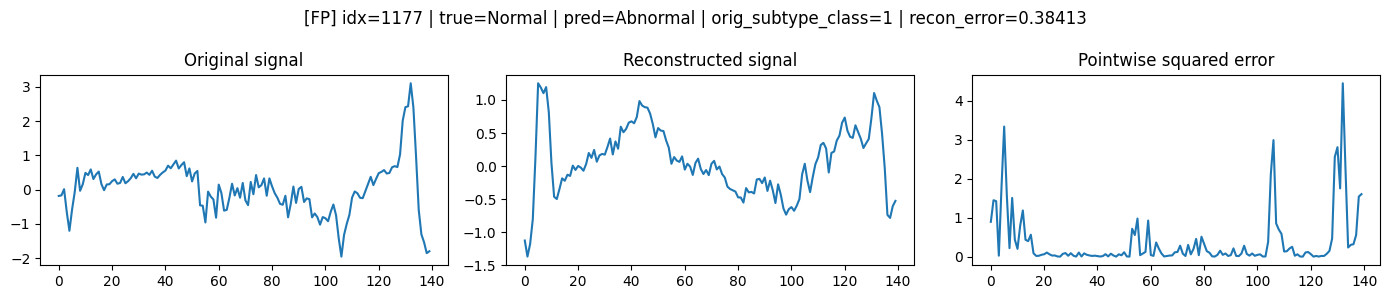

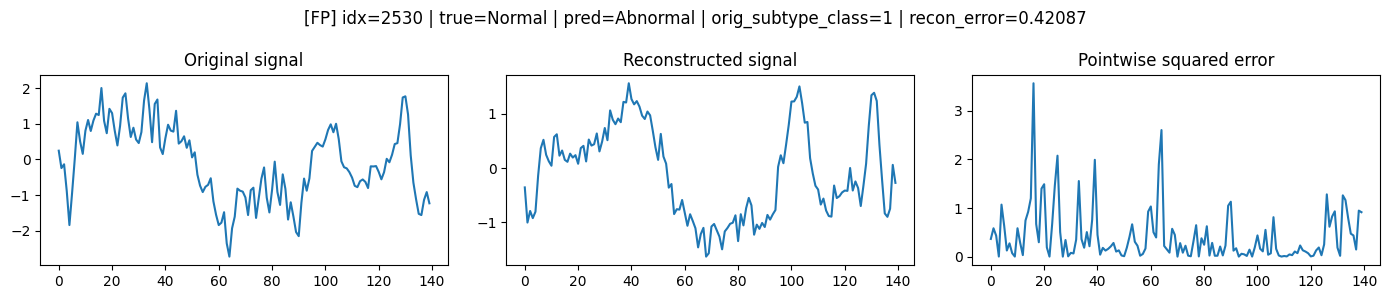

=== False Negatives ===


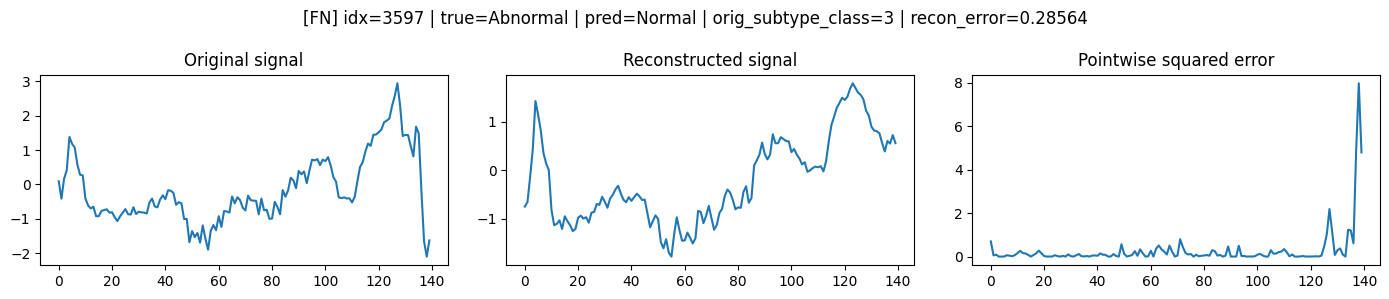

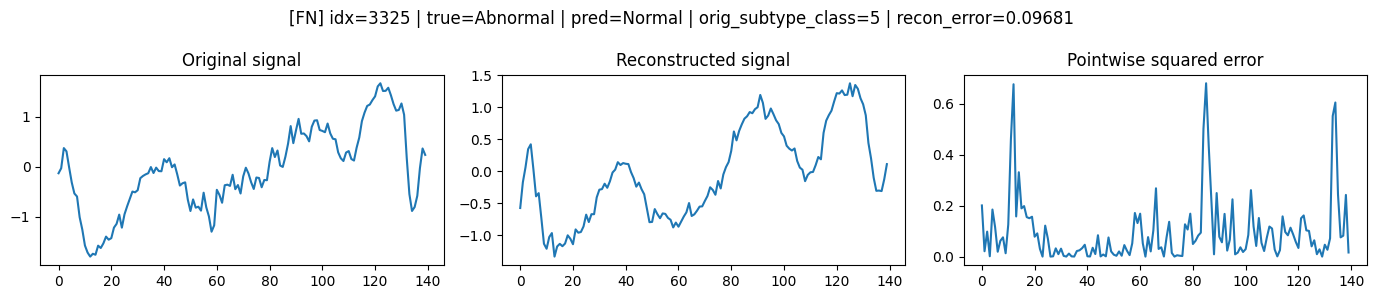

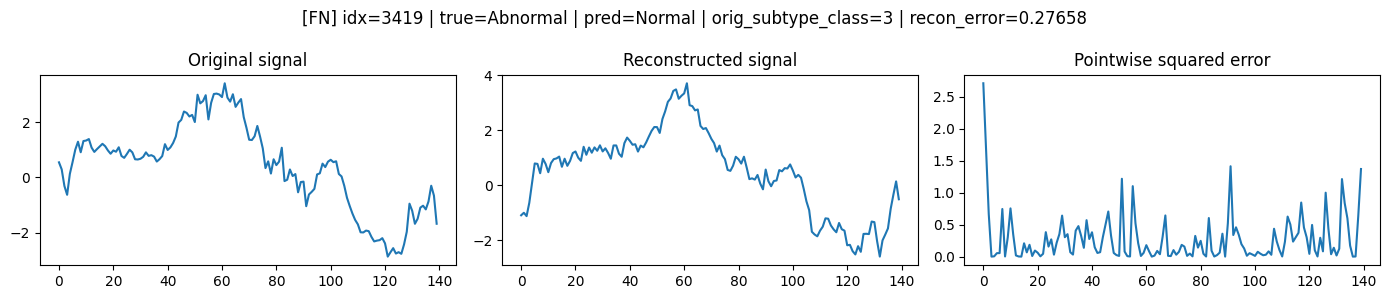

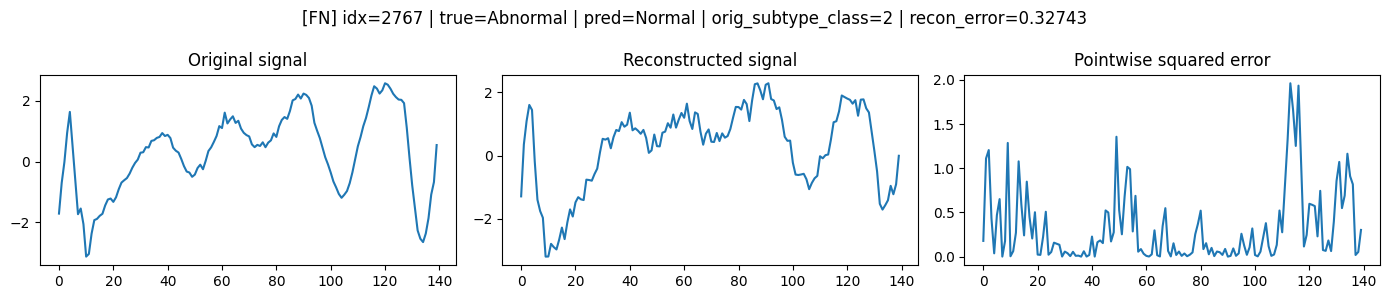

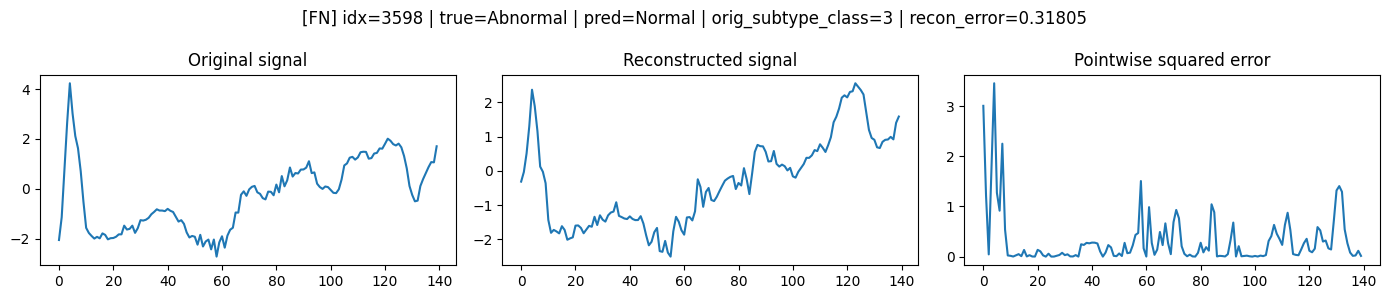

 class label_type  n_samples  mean_recon_error  std_recon_error
     1     Normal       2627          0.197067         0.484109
     2   Abnormal       1590          1.913022         1.288416
     3   Abnormal         86          2.476162         2.654409
     4   Abnormal        175          1.833734         2.582158
     5   Abnormal         22          3.250646         3.169894


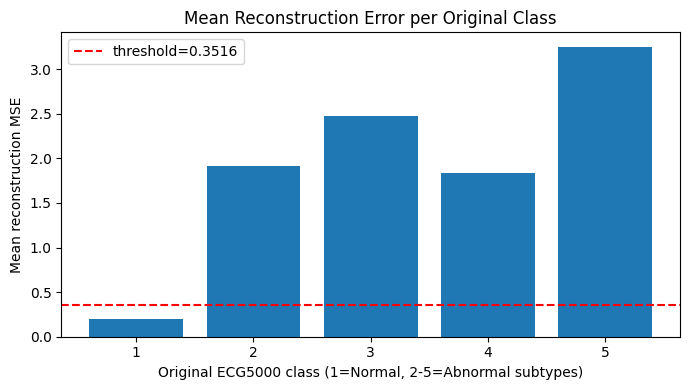

 subtype_class  n_total  n_true_positive  n_false_negative   recall
             2     1590             1589                 1 0.999371
             3       86               83                 3 0.965116
             4      175              175                 0 1.000000
             5       22               20                 2 0.909091
### Observations to inspect manually ###

a) Overlap between Normal/Abnormal error distributions (test):
   overlap range: [0.06012, 9.41191] exists=True
   test-normal points inside overlap range   : 2339 / 2627
   test-abnormal points inside overlap range : 1858 / 1873

b) Abnormal subtypes ranked by number of False Negatives:
 subtype_class  n_total  n_true_positive  n_false_negative   recall
             3       86               83                 3 0.965116
             5       22               20                 2 0.909091
             2     1590             1589                 1 0.999371
             4      175              175                 

In [ ]:

# Split rules
NORMAL_LABEL = 1

train_normal_mask = (y_train_raw == NORMAL_LABEL)
X_train_normal_all = X_train_raw[train_normal_mask]

from sklearn.model_selection import train_test_split
X_train_normal, X_val_normal = train_test_split(
    X_train_normal_all, test_size=0.20, random_state=SEED, shuffle=True
)

y_test_original = y_test_raw.copy()
y_test_binary = np.where(y_test_raw == NORMAL_LABEL, 0, 1)  # 0=Normal, 1=Abnormal

X_test_all = X_test_raw

print("train-normal:", X_train_normal.shape)
print("val-normal  :", X_val_normal.shape)
print("test total  :", X_test_all.shape,
      "| test-normal:", (y_test_binary == 0).sum(),
      "| test-abnormal:", (y_test_binary == 1).sum())
for c in range(1, 6):
    n = (y_test_original == c).sum()
    print(f"  test class {c}: {n} samples")

# Preprocessing

train_mean = X_train_normal.mean(axis=0, keepdims=True)
train_std = X_train_normal.std(axis=0, keepdims=True)
train_std[train_std == 0] = 1e-8  

def normalize(X):
    return (X - train_mean) / train_std

X_train_normal_n = normalize(X_train_normal)
X_val_normal_n = normalize(X_val_normal)
X_test_n = normalize(X_test_all)

# بررسی NaN/Inf
for name, arr in [("train_normal_n", X_train_normal_n), ("val_normal_n", X_val_normal_n), ("test_n", X_test_n)]:
    assert np.isfinite(arr).all(), f"{name} حاوی NaN یا Inf است!"
print("NaN/Inf check: OK")

# reshape به (samples, 140, 1)
X_train_normal_r = X_train_normal_n.reshape(-1, 140, 1)
X_val_normal_r = X_val_normal_n.reshape(-1, 140, 1)
X_test_r = X_test_n.reshape(-1, 140, 1)

print("\n--- Sample counts summary ---")
print(f"train-normal      : {X_train_normal_r.shape[0]}")
print(f"validation-normal : {X_val_normal_r.shape[0]}")
print(f"test-normal       : {(y_test_binary == 0).sum()}")
print(f"test-abnormal     : {(y_test_binary == 1).sum()}")

# Baseline model Dense Autoencoder
from tensorflow.keras import layers, models, callbacks, optimizers

def build_dense_autoencoder(input_dim=140, seed=SEED):
    inp = layers.Input(shape=(input_dim,), name="input")
    x = layers.Dense(64, activation="relu", name="enc_dense_64")(inp)
    x = layers.Dense(32, activation="relu", name="enc_dense_32")(x)
    bottleneck = layers.Dense(8, activation="relu", name="bottleneck")(x)
    x = layers.Dense(32, activation="relu", name="dec_dense_32")(bottleneck)
    x = layers.Dense(64, activation="relu", name="dec_dense_64")(x)
    out = layers.Dense(input_dim, activation="linear", name="reconstruction")(x)
    model = models.Model(inputs=inp, outputs=out, name="dense_autoencoder")
    model.compile(optimizer=optimizers.Adam(), loss="mse")
    return model

X_train_flat = X_train_normal_r.reshape(X_train_normal_r.shape[0], -1)
X_val_flat = X_val_normal_r.reshape(X_val_normal_r.shape[0], -1)
X_test_flat = X_test_r.reshape(X_test_r.shape[0], -1)

autoencoder = build_dense_autoencoder(input_dim=140, seed=SEED)
autoencoder.summary()
print("Total trainable params:", autoencoder.count_params())

early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True, verbose=1
)

history = autoencoder.fit(
    X_train_flat, X_train_flat,
    validation_data=(X_val_flat, X_val_flat),
    epochs=200,
    batch_size=64,
    shuffle=True,
    callbacks=[early_stop],
    verbose=2,
)

# Plot: train/validation loss
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

# Scoring: reconstruction MSE per sample

def reconstruction_mse(model, X_flat):
    recon = model.predict(X_flat, verbose=0)
    return np.mean(np.square(X_flat - recon), axis=1)

val_normal_errors = reconstruction_mse(autoencoder, X_val_flat)
test_errors_all = reconstruction_mse(autoencoder, X_test_flat)

test_normal_errors = test_errors_all[y_test_binary == 0]
test_abnormal_errors = test_errors_all[y_test_binary == 1]

print("val-normal error   : mean=%.5f std=%.5f" % (val_normal_errors.mean(), val_normal_errors.std()))
print("test-normal error  : mean=%.5f std=%.5f" % (test_normal_errors.mean(), test_normal_errors.std()))
print("test-abnormal error: mean=%.5f std=%.5f" % (test_abnormal_errors.mean(), test_abnormal_errors.std()))

# Threshold: base = percentile 95 of validation-normal, + sweep
base_threshold = np.percentile(val_normal_errors, 95)
print(f"Base threshold (95th percentile of validation-normal): {base_threshold:.6f}")

print("\n--- Threshold sweep on validation-normal only (no test leakage) ---")
sweep_percentiles = [90, 92, 94, 95, 96, 97, 98, 99]
sweep_rows = []
for p in sweep_percentiles:
    th = np.percentile(val_normal_errors, p)
    fp_rate = np.mean(val_normal_errors > th)  # false positive rate on validation-normal
    sweep_rows.append({"percentile": p, "threshold": th, "val_normal_false_positive_rate": fp_rate})

sweep_df = pd.DataFrame(sweep_rows)
print(sweep_df.to_string(index=False))

# threshold نهایی baseline = percentile 95 
final_threshold = base_threshold
print(f"\nFinal threshold used for test evaluation: {final_threshold:.6f}")

# 8) Final evaluation on TEST
y_pred = (test_errors_all > final_threshold).astype(int)  # 0=Normal, 1=Abnormal
y_true = y_test_binary

precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
accuracy = accuracy_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, test_errors_all)
pr_auc = average_precision_score(y_true, test_errors_all)

print("=== Final test metrics (threshold = %.6f) ===" % final_threshold)
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1        : {f1:.4f}")
print(f"Accuracy  : {accuracy:.4f}  <-- NOTE: due to class imbalance, accuracy is NOT the primary metric")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Abnormal"], zero_division=0))

cm = confusion_matrix(y_true, y_pred)
print("Confusion matrix (rows=true, cols=pred), order [Normal, Abnormal]:")
print(cm)

# 9) Plot: Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
labels = ["Normal", "Abnormal"]
ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix (Test)")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im)
plt.tight_layout()
plt.show()

# 10) Plot: Histogram/KDE of reconstruction error distributions
plt.figure(figsize=(8, 5))
bins = 50
plt.hist(val_normal_errors, bins=bins, alpha=0.5, density=True, label="validation-normal")
plt.hist(test_normal_errors, bins=bins, alpha=0.5, density=True, label="test-normal")
plt.hist(test_abnormal_errors, bins=bins, alpha=0.5, density=True, label="test-abnormal")
plt.axvline(final_threshold, color="red", linestyle="--", label=f"threshold={final_threshold:.4f}")
plt.xlabel("Reconstruction MSE")
plt.ylabel("Density")
plt.title("Reconstruction Error Distributions")
plt.legend()
plt.tight_layout()
plt.show()

# Plot: Boxplot / Violin plot (test Normal vs Abnormal)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot([test_normal_errors, test_abnormal_errors], labels=["Normal", "Abnormal"])
axes[0].axhline(final_threshold, color="red", linestyle="--")
axes[0].set_title("Boxplot — Test Reconstruction Error")
axes[0].set_ylabel("Reconstruction MSE")

axes[1].violinplot([test_normal_errors, test_abnormal_errors], showmedians=True)
axes[1].set_xticks([1, 2]); axes[1].set_xticklabels(["Normal", "Abnormal"])
axes[1].axhline(final_threshold, color="red", linestyle="--")
axes[1].set_title("Violin plot — Test Reconstruction Error")
plt.tight_layout()
plt.show()

# TP / FP / FN sample inspection 5 each: original vs reconstructed vs error
recon_test_flat = autoencoder.predict(X_test_flat, verbose=0)
pointwise_sq_err = np.square(X_test_flat - recon_test_flat)  # (N, 140)

tp_idx = np.where((y_true == 1) & (y_pred == 1))[0]
fp_idx = np.where((y_true == 0) & (y_pred == 1))[0]
fn_idx = np.where((y_true == 1) & (y_pred == 0))[0]

rng = np.random.RandomState(SEED)

def pick(idx_array, k=5):
    if len(idx_array) == 0:
        return np.array([], dtype=int)
    k = min(k, len(idx_array))
    return rng.choice(idx_array, size=k, replace=False)

tp_sample = pick(tp_idx)
fp_sample = pick(fp_idx)
fn_sample = pick(fn_idx)

def plot_case_group(indices, group_name):
    if len(indices) == 0:
        print(f"No samples available for group: {group_name}")
        return
    for i in indices:
        true_lbl = "Normal" if y_true[i] == 0 else "Abnormal"
        pred_lbl = "Normal" if y_pred[i] == 0 else "Abnormal"
        subtype = int(y_test_original[i])
        err = test_errors_all[i]

        fig, axes = plt.subplots(1, 3, figsize=(14, 3))
        axes[0].plot(X_test_flat[i])
        axes[0].set_title("Original signal")
        axes[1].plot(recon_test_flat[i])
        axes[1].set_title("Reconstructed signal")
        axes[2].plot(pointwise_sq_err[i])
        axes[2].set_title("Pointwise squared error")

        fig.suptitle(
            f"[{group_name}] idx={i} | true={true_lbl} | pred={pred_lbl} | "
            f"orig_subtype_class={subtype} | recon_error={err:.5f}"
        )
        plt.tight_layout()
        plt.show()

print("=== True Positives ===")
plot_case_group(tp_sample, "TP")
print("=== False Positives ===")
plot_case_group(fp_sample, "FP")
print("=== False Negatives ===")
plot_case_group(fn_sample, "FN")

# 13) Mean reconstruction error per original class (1..5)
class_error_rows = []
for c in range(1, 6):
    mask = (y_test_original == c)
    if mask.sum() == 0:
        continue
    class_error_rows.append({
        "class": c,
        "label_type": "Normal" if c == 1 else "Abnormal",
        "n_samples": int(mask.sum()),
        "mean_recon_error": float(test_errors_all[mask].mean()),
        "std_recon_error": float(test_errors_all[mask].std()),
    })
class_error_df = pd.DataFrame(class_error_rows)
print(class_error_df.to_string(index=False))

plt.figure(figsize=(7, 4))
plt.bar(class_error_df["class"].astype(str), class_error_df["mean_recon_error"])
plt.axhline(final_threshold, color="red", linestyle="--", label=f"threshold={final_threshold:.4f}")
plt.xlabel("Original ECG5000 class (1=Normal, 2-5=Abnormal subtypes)")
plt.ylabel("Mean reconstruction MSE")
plt.title("Mean Reconstruction Error per Original Class")
plt.legend()
plt.tight_layout()
plt.show()

# False Negatives and Recall per abnormal subtype (classes 2..5)
subtype_rows = []
for c in range(2, 6):
    mask = (y_test_original == c)
    n_total = int(mask.sum())
    if n_total == 0:
        continue
    n_fn = int(np.sum(mask & (y_pred == 0)))  # true abnormal, predicted normal
    n_tp = int(np.sum(mask & (y_pred == 1)))
    recall_c = n_tp / n_total if n_total > 0 else np.nan
    subtype_rows.append({
        "subtype_class": c,
        "n_total": n_total,
        "n_true_positive": n_tp,
        "n_false_negative": n_fn,
        "recall": recall_c,
    })
subtype_df = pd.DataFrame(subtype_rows)
print(subtype_df.to_string(index=False))

#  Observations to inspect manually
print("### Observations to inspect manually ###\n")

overlap_lo = max(test_normal_errors.min(), test_abnormal_errors.min())
overlap_hi = min(test_normal_errors.max(), test_abnormal_errors.max())
overlap_region_exists = overlap_lo < overlap_hi
n_normal_in_overlap = np.sum((test_normal_errors >= overlap_lo) & (test_normal_errors <= overlap_hi)) if overlap_region_exists else 0
n_abnormal_in_overlap = np.sum((test_abnormal_errors >= overlap_lo) & (test_abnormal_errors <= overlap_hi)) if overlap_region_exists else 0
print("a) Overlap between Normal/Abnormal error distributions (test):")
print(f"   overlap range: [{overlap_lo:.5f}, {overlap_hi:.5f}] exists={overlap_region_exists}")
print(f"   test-normal points inside overlap range   : {n_normal_in_overlap} / {len(test_normal_errors)}")
print(f"   test-abnormal points inside overlap range : {n_abnormal_in_overlap} / {len(test_abnormal_errors)}\n")

print("b) Abnormal subtypes ranked by number of False Negatives:")
print(subtype_df.sort_values("n_false_negative", ascending=False).to_string(index=False))
print()

print("c) Top False Positive samples by reconstruction error:")
if len(fp_idx) > 0:
    fp_top = pd.DataFrame({
        "idx": fp_idx,
        "recon_error": test_errors_all[fp_idx],
        "orig_class": y_test_original[fp_idx],
    }).sort_values("recon_error", ascending=False).head(10)
    print(fp_top.to_string(index=False))
else:
    print("   No False Positive samples.")
print()

print("d) Bottom False Negative samples by reconstruction error (closest to threshold):")
if len(fn_idx) > 0:
    fn_bottom = pd.DataFrame({
        "idx": fn_idx,
        "recon_error": test_errors_all[fn_idx],
        "orig_class": y_test_original[fn_idx],
    }).sort_values("recon_error", ascending=True).head(10)
    print(fn_bottom.to_string(index=False))
else:
    print("   No False Negative samples.")
print()

median_normal = np.median(test_normal_errors)
median_abnormal = np.median(test_abnormal_errors)
print("e) Median reconstruction error gap (test):")
print(f"   median(test-normal)   = {median_normal:.6f}")
print(f"   median(test-abnormal) = {median_abnormal:.6f}")
print(f"   gap (abnormal - normal) = {median_abnormal - median_normal:.6f}\n")

val_fp_rate_at_final_threshold = np.mean(val_normal_errors > final_threshold)
print("f) False positive rate on validation-normal at the selected (95th percentile) threshold:")
print(f"   threshold = {final_threshold:.6f}")
print(f"   FP rate on validation-normal = {val_fp_rate_at_final_threshold:.4f}")

print("\n--- Summary table ---")
summary_df = pd.DataFrame([{
    "final_threshold": final_threshold,
    "test_precision": precision,
    "test_recall": recall,
    "test_f1": f1,
    "test_accuracy": accuracy,
    "test_roc_auc": roc_auc,
    "test_pr_auc": pr_auc,
    "val_normal_fp_rate": val_fp_rate_at_final_threshold,
    "median_gap_abnormal_minus_normal": median_abnormal - median_normal,
}])
print(summary_df.to_string(index=False))


In [6]:
from google.colab import files
uploaded = files.upload()


Saving ecg5000-threshold-analysis (2) (1).zip to ecg5000-threshold-analysis (2) (1) (1).zip


In [8]:
!pip install scikit-learn matplotlib pandas numpy


In [9]:
model = autoencoder
X_val_normal_scaled = X_val_normal_n
X_test_scaled = X_test_n
X_train_normal_scaled = X_train_normal_n
threshold_base = final_threshold


val-normal errors  : n=59 mean=0.254921 std=0.928133
test errors         : n=4500 mean=0.925504 std=1.387524

=== Per-alpha threshold table ===
 alpha  selected_threshold  validation_normal_FPR  n_val_normal_above_threshold
 0.100            0.275739               0.084746                             5
 0.070            0.287671               0.067797                             4
 0.050            0.528365               0.033898                             2
 0.035            0.528365               0.033898                             2
 0.020            0.742255               0.016949                             1

=== Final comparison table (sorted by threshold) ===
                        method  alpha  threshold  validation_FPR  test_precision  test_recall  test_F1  test_FP  test_FN  recall_class_2  recall_class_3  recall_class_4  recall_class_5
  false_alarm_budget_alpha_0.1  0.100   0.275739        0.084746        0.863007     0.998932 0.926008      297        2        1.000000 

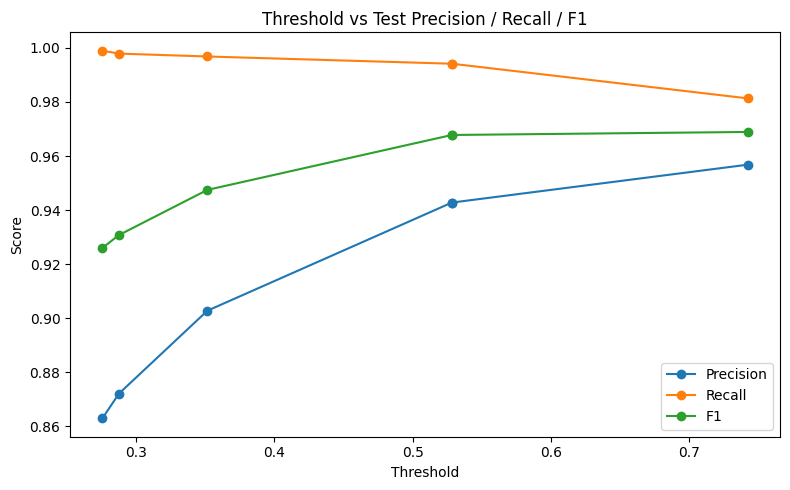

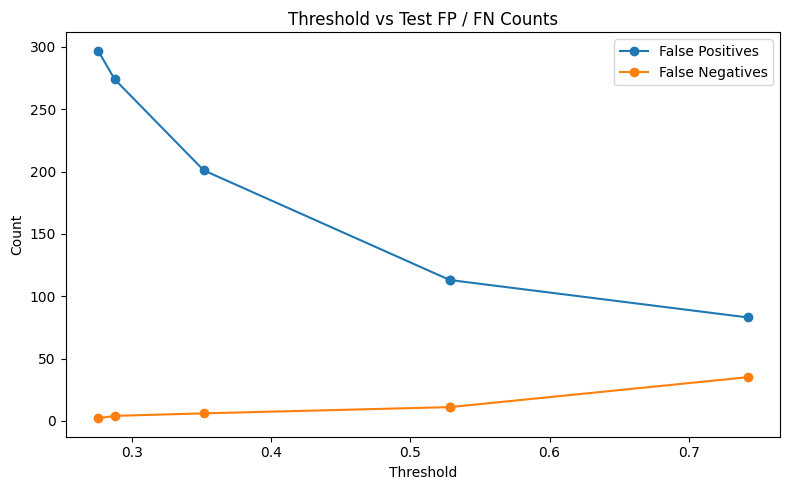

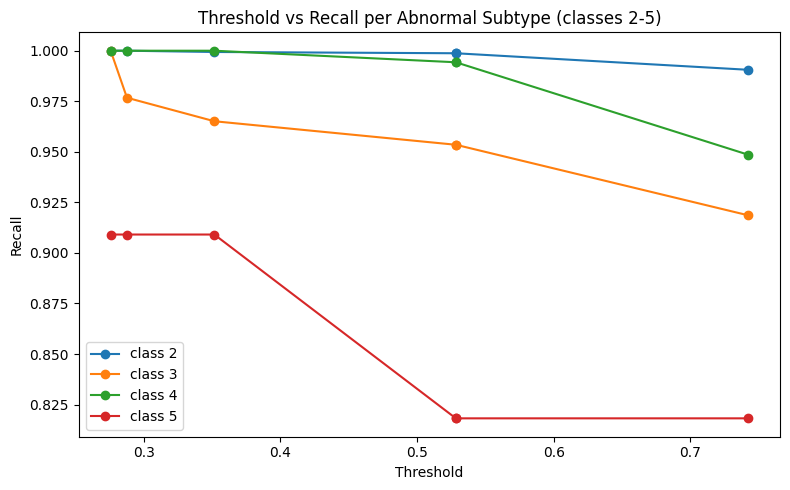

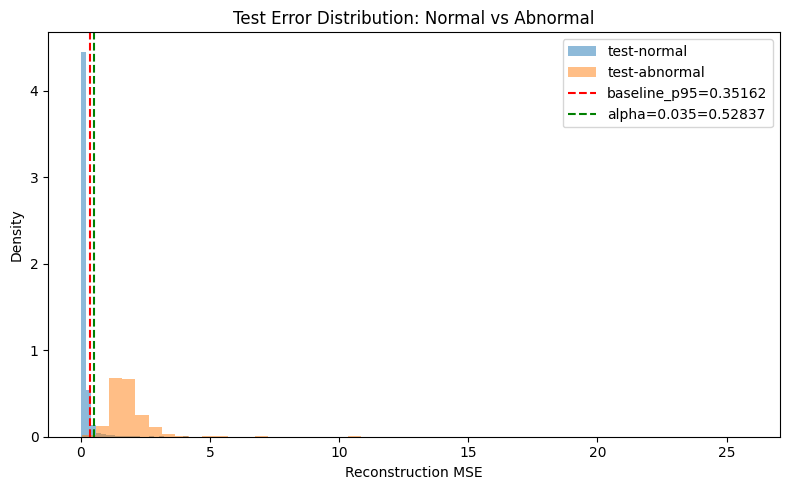

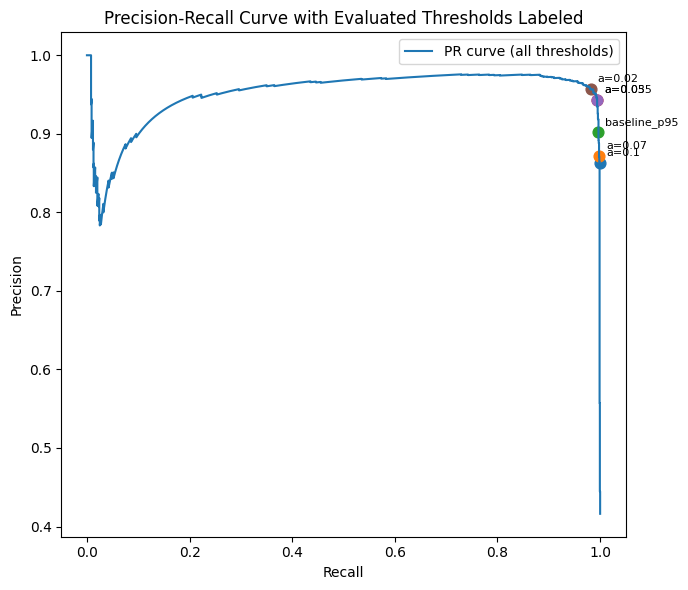


=== Bootstrap stability of threshold (alpha=0.035, n_bootstrap=1000) ===
mean   = 1.022971
median = 0.528365
std    = 1.838514
95% percentile interval = [0.216627, 7.270057]


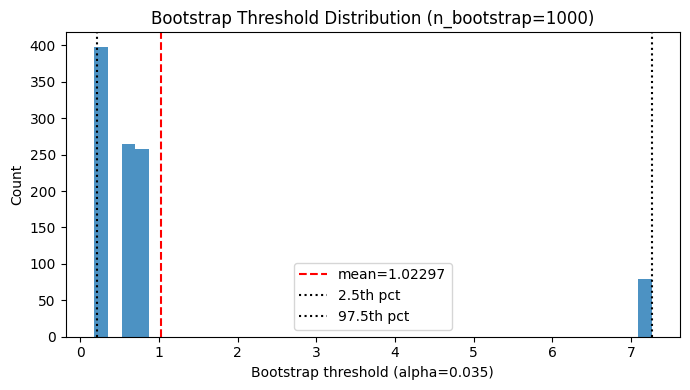


### Interpretation prompts — do not fabricate conclusions ###

1) Validation FPR vs test FP, per method (raw numbers to compare):
                        method  validation_FPR  test_FP
  false_alarm_budget_alpha_0.1        0.084746      297
 false_alarm_budget_alpha_0.07        0.067797      274
                  baseline_p95        0.050847      201
 false_alarm_budget_alpha_0.05        0.033898      113
false_alarm_budget_alpha_0.035        0.033898      113
 false_alarm_budget_alpha_0.02        0.016949       83

2) F1 per method (raw numbers):
                        method  threshold  test_F1
 false_alarm_budget_alpha_0.02   0.742255 0.968898
 false_alarm_budget_alpha_0.05   0.528365 0.967775
false_alarm_budget_alpha_0.035   0.528365 0.967775
                  baseline_p95   0.351620 0.947475
 false_alarm_budget_alpha_0.07   0.287671 0.930777
  false_alarm_budget_alpha_0.1   0.275739 0.926008

3) Recall class 5 across methods, ordered by threshold (raw numbers):
                

In [10]:
import sys
sys.path.append("/content/ecg5000-threshold-analysis")

from threshold_analysis import run_analysis

results = run_analysis(
    model=model,
    X_val_normal_scaled=X_val_normal_scaled,
    X_test_scaled=X_test_scaled,
    y_test_binary=y_test_binary,
    y_test_original=y_test_original,
    threshold_base=threshold_base,
)


OCSVM val-normal scores    : mean=-0.122181 std=0.178955
OCSVM test scores          : mean=0.154321 std=0.355584
IsoForest val-normal scores: mean=-0.091106 std=0.061345
IsoForest test scores      : mean=-0.031942 std=0.087355

=== One-Class SVM — false-alarm-budget results ===
           method  alpha  threshold  validation_FPR  test_precision  test_recall  test_F1  test_accuracy  test_FP  test_FN  recall_class_2  recall_class_3  recall_class_4  recall_class_5
  ocsvm_alpha_0.1  0.100   0.112183        0.084746        0.896154     0.995195 0.943081       0.950000      216        9        0.999371        0.976744        0.988571        0.818182
 ocsvm_alpha_0.07  0.070   0.182922        0.067797        0.920792     0.993059 0.955561       0.961556      160       13        0.998113        0.976744        0.977143        0.818182
 ocsvm_alpha_0.05  0.050   0.221782        0.033898        0.928929     0.990924 0.958925       0.964667      142       17        0.998113        0.941860      

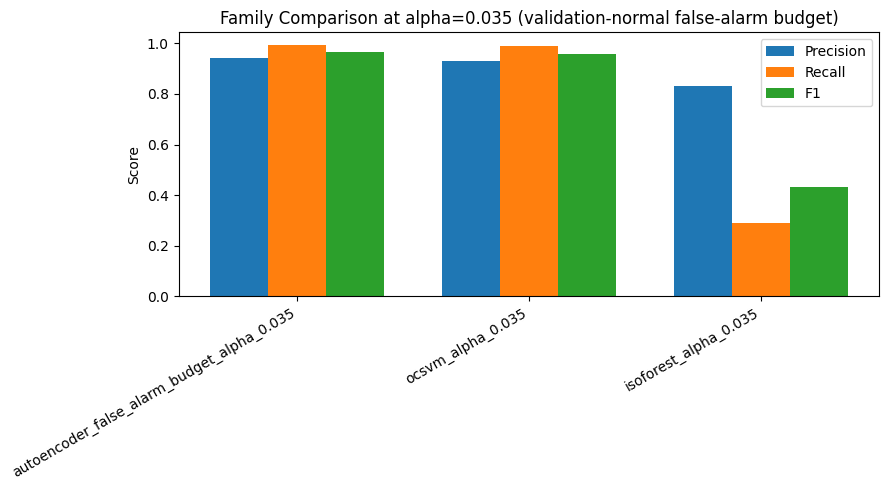

In [11]:
from stretch_baselines import run_stretch_comparison

stretch_results = run_stretch_comparison(
    X_train_normal_scaled=X_train_normal_scaled,
    X_val_normal_scaled=X_val_normal_scaled,
    X_test_scaled=X_test_scaled,
    y_test_binary=y_test_binary,
    y_test_original=y_test_original,
    autoencoder_final_table=results["final_table"],
)


In [ ]:
import os
import json
import pandas as pd

output_dir = "/content/ecg5000_outputs"
os.makedirs(output_dir, exist_ok=True)

results["final_table"].to_csv(os.path.join(output_dir, "ae_final_table.csv"), index=False)
results["alpha_table"].to_csv(os.path.join(output_dir, "ae_alpha_table.csv"), index=False)

stretch_results["combined_table"].to_csv(os.path.join(output_dir, "stretch_combined_table.csv"), index=False)
stretch_results["ocsvm_table"].to_csv(os.path.join(output_dir, "ocsvm_table.csv"), index=False)
stretch_results["isoforest_table"].to_csv(os.path.join(output_dir, "isoforest_table.csv"), index=False)

boot = results.get("bootstrap_thresholds", None)
if boot is not None:
    pd.Series(boot).to_csv(os.path.join(output_dir, "bootstrap_thresholds.csv"), index=False, header=["threshold"])

summary = {
    "ae_best_row": results["final_table"].iloc[0].to_dict() if len(results["final_table"]) else {},
    "ae_alpha_best_row": results["alpha_table"].iloc[0].to_dict() if len(results["alpha_table"]) else {},
    "stretch_best_row": stretch_results["combined_table"].iloc[0].to_dict() if len(stretch_results["combined_table"]) else {},
}
with open(os.path.join(output_dir, "summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("Saved to:", output_dir)
print(os.listdir(output_dir))


Saved to: /content/ecg5000_outputs
['ae_final_table.csv', 'stretch_combined_table.csv', 'bootstrap_thresholds.csv', 'summary.json', 'ocsvm_table.csv', 'ae_alpha_table.csv', 'isoforest_table.csv']


In [13]:
import matplotlib.pyplot as plt
import os

plot_dir = "/content/ecg5000_outputs/plots"
os.makedirs(plot_dir, exist_ok=True)

for i, num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(num)
    fig.savefig(os.path.join(plot_dir, f"figure_{i}.png"), dpi=200, bbox_inches="tight")

print("Saved plots to:", plot_dir)
print(os.listdir(plot_dir))


Saved plots to: /content/ecg5000_outputs/plots
[]
